# 10 · The protocol and the fixed baseline (work package 2)

**Work package 2** of the [implementation plan](../../research/implementation_plan.md): measure the fixed baseline
on all 21 development points before any model is compared with it.

- **Task at a point *t*:** for every evaluated account, rank every token it has never traded; a hit is a token it
  trades for the first time in the two days after *t*.
- **Evaluated accounts:** at least one token in the 14 days before *t* and at least one new token in the target.
- **Fixed baseline:** the 10 tokens with the most distinct accounts in the 14 days before *t*, skipping the
  account's own. No settings.
- **Points:** 10 in Dev A (2 to 20 July), 11 in Dev B (22 July to 11 August). The 14 test points are not touched.

The protocol is in `src/scripts/protocol.py`, the statistics in `src/scripts/stats.py`.

In [1]:
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import pandas as pd

import plots
import protocol as pc
import stats
import token_data as td

plots.style()
pd.set_option("display.float_format", "{:,.3f}".format)
OUT = pc.RESULTS_DIR / "wp2"
OUT.mkdir(parents=True, exist_ok=True)

legs = td.load_legs()
DEV_POINTS = pc.POINTS["dev_a"] + pc.POINTS["dev_b"]
print(f"{len(DEV_POINTS)} development points, from {DEV_POINTS[0]:%d %b} to {DEV_POINTS[-1]:%d %b}")

21 development points, from 02 Jul to 11 Aug


## 0. Check: the protocol code reproduces the feasibility study

`protocol.py` is new code. Before it is trusted, it is run on the 14 days of the feasibility study (24 September
to 8 October, data that is **not** part of the project and is used here only to check code), with the evaluation
points placed where notebook 05 placed them. Notebook 05 reported the baseline's recall@10 after day 4 to day 10
as 0.201, 0.185, 0.161, 0.157, 0.128, 0.114 and 0.142. Notebook 05 cut its targets by block number, the new code by
time, so tiny differences are expected.

In [2]:
import dex_swaps as ds

START, DAY = 26_049_600, 7_200  # notebook 05: first block, blocks per day
NOTEBOOK_05 = [0.201, 0.185, 0.161, 0.157, 0.128, 0.114, 0.142]

swaps = ds.load_swaps(ds.DATA_DIR, START, START + 14 * DAY - 1)
check_legs = td.legs_with_time_and_pool(swaps, ds.load_pool_tokens(swaps["pool"].unique()))
block_time = swaps.drop_duplicates("block").set_index("block")["timestamp"]


def time_of(block):
    """The time of the first block at or after `block` (notebook 05 placed its points on block numbers)."""
    return block_time[block_time.index >= block].iloc[0]


base = td.base_tokens(check_legs, check_legs["timestamp"].min(), time_of(START + 10 * DAY))
check_legs = check_legs[~check_legs["token"].isin(set(base.loc[base["is_base"], "token"]))]
check_legs = check_legs.assign(user=td.IdMap().encode(check_legs["user"]), token=td.IdMap().encode(check_legs["token"]))

rows = []
for day, reported in zip(range(4, 11), NOTEBOOK_05):
    task = pc.make_task(check_legs, time_of(START + day * DAY))
    per_user, _ = pc.evaluate_point(pc.popularity_scorer(task), task)
    rows.append({"point": f"after day {day}", "notebook 05": reported, "new code": round(per_user["recall"].mean(), 3)})
del swaps, check_legs
pd.DataFrame(rows)

,point,notebook 05,new code
0,after day 4,0.201,0.201
1,after day 5,0.185,0.185
2,after day 6,0.161,0.161
3,after day 7,0.157,0.157
4,after day 8,0.128,0.128
5,after day 9,0.114,0.110
6,after day 10,0.142,0.142


Six of the seven points agree to the third decimal; the seventh differs by 0.004 because about 50 accounts are
evaluated or not depending on whether the target ends after 14,400 blocks or after exactly two days. The protocol
code computes what notebook 05 computed.

## 1. The size of the task at each point

The analogue of Table 7 of the project plan. `cold_share` is the share of positive pairs whose token did not exist
before *t*: no model of past trades can list them, so they cap recall below 1.

Building a task takes a few seconds; tasks are cached in `data/project/tasks/` for the later notebooks.

In [3]:
sizes = pc.task_sizes(legs, DEV_POINTS)
sizes.to_csv(OUT / "task_sizes_dev.csv", index=False)
sizes

,point,part,users_in_history,tokens_in_history,users_evaluated,positive_pairs,cold_share
0,2026-07-02 00:00:00+00:00,dev_a,170358,19985,9606,22008,0.226
1,2026-07-04 00:00:00+00:00,dev_a,187847,21790,11916,27400,0.315
2,2026-07-06 00:00:00+00:00,dev_a,207616,23838,13922,26521,0.308
3,2026-07-08 00:00:00+00:00,dev_a,224402,25085,6685,17972,0.170
4,2026-07-10 00:00:00+00:00,dev_a,239271,27053,5675,14864,0.179
5,2026-07-12 00:00:00+00:00,dev_a,253746,28105,5091,14438,0.218
6,2026-07-14 00:00:00+00:00,dev_a,264835,29741,5614,14366,0.220
7,2026-07-16 00:00:00+00:00,dev_a,276769,30673,5626,14762,0.249
8,2026-07-18 00:00:00+00:00,dev_a,288406,31776,4210,12736,0.265
9,2026-07-20 00:00:00+00:00,dev_a,298192,33664,5137,13920,0.263


## 2. The baseline, and recent popularity, at every development point

*Recent popularity* counts the accounts of the last day only. The plan reports it next to the baseline because
how much recent activity should count is one of the project's core problems (time weighting).

In [4]:
baseline = pc.run("popularity (baseline)", pc.popularity_scorer, legs, DEV_POINTS, verbose=False)
recent = pc.run("recent popularity", lambda task: pc.popularity_scorer(task, days=1), legs, DEV_POINTS, verbose=False)

baseline.per_point.to_csv(OUT / "baseline_dev.csv", index=False)
recent.per_point.to_csv(OUT / "recent_popularity_dev.csv", index=False)

In [5]:
columns = ["point", "part", "users", "recall", "recall_low", "recall_high", "ndcg", "hit_rate", "coverage", "recall_no_head"]
baseline.per_point[columns]

,point,part,users,recall,recall_low,recall_high,ndcg,hit_rate,coverage,recall_no_head
0,2026-07-02 00:00:00+00:00,dev_a,9606,0.086,0.081,0.092,0.044,0.111,0.002,0.000
1,2026-07-04 00:00:00+00:00,dev_a,11916,0.054,0.050,0.058,0.030,0.075,0.002,0.000
2,2026-07-06 00:00:00+00:00,dev_a,13922,0.033,0.031,0.036,0.023,0.050,0.001,0.000
3,2026-07-08 00:00:00+00:00,dev_a,6685,0.086,0.080,0.092,0.056,0.117,0.001,0.000
4,2026-07-10 00:00:00+00:00,dev_a,5675,0.061,0.055,0.066,0.045,0.086,0.001,0.000
5,2026-07-12 00:00:00+00:00,dev_a,5091,0.066,0.060,0.073,0.047,0.097,0.001,0.000
6,2026-07-14 00:00:00+00:00,dev_a,5614,0.076,0.069,0.083,0.054,0.108,0.001,0.000
7,2026-07-16 00:00:00+00:00,dev_a,5626,0.078,0.072,0.085,0.055,0.115,0.001,0.000
8,2026-07-18 00:00:00+00:00,dev_a,4210,0.071,0.064,0.078,0.053,0.110,0.002,0.000
9,2026-07-20 00:00:00+00:00,dev_a,5137,0.135,0.128,0.144,0.097,0.185,0.002,0.000


`recall_low` and `recall_high` are the 95% bootstrap interval over accounts at that point: the sampling noise
*within* a point. Compare its width with how much recall moves *between* points.

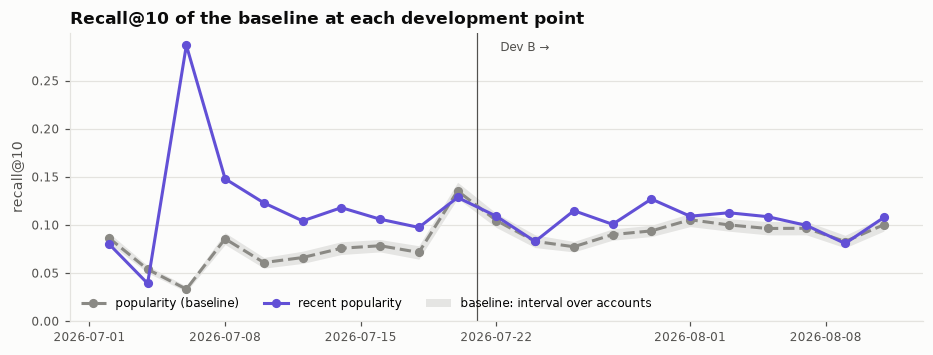

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.4))
plots.per_point_lines(ax, {"popularity (baseline)": baseline.per_point, "recent popularity": recent.per_point})
ax.fill_between(baseline.per_point["point"], baseline.per_point["recall_low"], baseline.per_point["recall_high"],
                color=plots.BASELINE_GREY, alpha=0.2, linewidth=0, label="baseline: interval over accounts")  # fmt: skip
ax.axvline(pc.DEV_B_START - pd.Timedelta(days=1), color=plots.INK_SECONDARY, linewidth=0.8)
ax.text(pc.DEV_B_START, 0.97, " Dev B →", transform=ax.get_xaxis_transform(), va="top", fontsize=8, color=plots.INK_SECONDARY)
ax.set_ylabel("recall@10")
ax.set_title("Recall@10 of the baseline at each development point")
ax.legend(loc="lower left", ncols=3)
plt.show()

## 3. Paired comparison: recent popularity against the baseline

The comparison every later notebook makes. For each point, *d* = recall(model) − recall(baseline); the table gives
the mean of *d*, its 95% bootstrap interval over points, the number of points won, and an exact sign test.

In [7]:
for part in ("dev_a", "dev_b"):
    results = {
        "popularity (baseline)": baseline.per_point.query("part == @part"),
        "recent popularity": recent.per_point.query("part == @part"),
    }
    print(part)
    display(stats.compare(results, baseline="popularity (baseline)"))

dev_a


,model,points,mean,lowest,highest,mean_difference,interval_low,interval_high,wins,sign_test_p
0,popularity (baseline),10,0.075,0.033,0.135,NaN,NaN,NaN,NaN,NaN
1,recent popularity,10,0.123,0.039,0.287,0.048,0.012,0.100,7 of 10,0.344


dev_b


,model,points,mean,lowest,highest,mean_difference,interval_low,interval_high,wins,sign_test_p
0,popularity (baseline),11,0.094,0.077,0.105,NaN,NaN,NaN,NaN,NaN
1,recent popularity,11,0.105,0.081,0.127,0.011,0.005,0.019,9 of 11,0.065


## 4. Who the baseline serves: recall by the size of the account's history

Accounts are grouped by the number of tokens they traded in the 14 days before *t*. The plan expects the baseline to
be weakest for accounts with long histories, which is where a personalized model has the most to work with.

In [8]:
users = baseline.per_user
by_group = users.groupby("group").agg(evaluations=("recall", "size"), recall=("recall", "mean"), hit_rate=("hit", "mean"))
by_group.to_csv(OUT / "baseline_dev_by_group.csv")
by_group

,evaluations,recall,hit_rate
group,,,
1,39706,0.128,0.152
2-4,39756,0.092,0.119
5+,61910,0.043,0.098


## 5. Why is the baseline lower than in the feasibility study?

In the feasibility study (24 September to 8 October) the baseline found 15.5% of the new tokens; here it finds
7.5% on Dev A and 9.4% on Dev B. Section 0 shows that the code is not the reason. Two properties of June to August are:

- **More cold start.** A larger share of the tokens accounts pick up did not exist at *t* and cannot be listed by
  any model of past trades. `recall_if_no_cold` divides recall by the share that is not cold: roughly, the recall
  on the tokens that could have been listed.
- **Fast-rising tokens.** On some points many accounts pick up a token launched days before. It is not yet among
  the most popular of 14 days, but it is among the most popular of the last day: on 6 July recent popularity
  finds 28.7% of the new tokens and the baseline 3.3%.

In [9]:
why = sizes[["point", "part", "users_evaluated", "cold_share"]].merge(baseline.per_point[["point", "recall"]], on="point")
why = why.merge(recent.per_point[["point", "recall"]].rename(columns={"recall": "recall_recent"}), on="point")
why["recall_if_no_cold"] = why["recall"] / (1 - why["cold_share"])
why.groupby("part")[["users_evaluated", "cold_share", "recall", "recall_if_no_cold", "recall_recent"]].mean()

,users_evaluated,cold_share,recall,recall_if_no_cold,recall_recent
part,,,,,
dev_a,"7,348.200",0.241,0.075,0.098,0.123
dev_b,"6,171.818",0.312,0.094,0.137,0.105


## Reading

- **The protocol code is right.** It reproduces the feasibility study's baseline (section 0).
- **The baseline finds 7.5% (Dev A) and 9.4% (Dev B) of the tokens an account picks up next**, half of the 15.5% of
  the feasibility study. It moves from 3.3% to 13.5% between Dev A points and from 7.7% to 10.5% between Dev B
  points, while the sampling interval within a point is about ±0.006: as in the feasibility study, the point
  matters far more than the sample, so models are compared point by point.
- **The task is harder in this period:** 24% (Dev A) and 31% (Dev B) of the positive pairs are cold start, against
  15 to 25% in the feasibility study. This is the ceiling problem of core problem 3, and it is larger than planned.
- **Recent activity matters here, unlike in the feasibility study.** Recent popularity beats the baseline at 7 of
  10 Dev A points and 9 of 11 Dev B points, and the bootstrap interval of the mean difference excludes zero in both
  parts (+0.048 on Dev A, driven by 6 July; +0.011 on Dev B). In the feasibility study it won 2 of 7. This is the
  question of core problem 2 (time weighting), and the data says it is worth asking.
- **The baseline is weakest where personalization should help:** recall 0.128 for accounts with one token in
  their history, 0.092 with two to four, 0.043 with five or more.
- **Nothing in the plan changes.** The baseline stays as defined (14 days, no settings); recent popularity is a
  reference, and how much recent activity should count is tuned in work package 4.